# Lending Club Loan Data Analysis — Deep Learning

**Objective:** predict whether a loan will **not be fully paid** (`not.fully.paid = 1`, i.e. default) using LendingClub data from 2007-2015.
The data is imbalanced (~16% defaults). Steps: feature transformation → EDA → feature engineering (drop highly correlated features) →
Keras / TensorFlow neural network.

In [1]:
import os, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, precision_recall_curve, f1_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 100
print("TensorFlow", tf.__version__)

df = pd.read_csv("../loan_data.csv")
print(df.shape)
df.head()

TensorFlow 2.21.0
(9578, 14)


,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [2]:
df.info()
print("Missing values:", df.isna().sum().sum(), "| Duplicates:", df.duplicated().sum())
df.describe().T.round(3)

<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), str(1)
memory usage: 1.0 MB
Missing values: 0 | Duplicates: 0


,count,mean,std,min,25%,50%,75%,max
credit.policy,9578.0,0.805,0.396,0.000,1.000,1.000,1.000,1.000
int.rate,9578.0,0.123,0.027,0.060,0.104,0.122,0.141,0.216
installment,9578.0,319.089,207.071,15.670,163.770,268.950,432.762,940.140
log.annual.inc,9578.0,10.932,0.615,7.548,10.558,10.929,11.291,14.528
dti,9578.0,12.607,6.884,0.000,7.212,12.665,17.950,29.960
fico,9578.0,710.846,37.971,612.000,682.000,707.000,737.000,827.000
days.with.cr.line,9578.0,4560.767,2496.930,178.958,2820.000,4139.958,5730.000,17639.958
revol.bal,9578.0,16913.964,33756.190,0.000,3187.000,8596.000,18249.500,1207359.000
revol.util,9578.0,46.799,29.014,0.000,22.600,46.300,70.900,119.000
inq.last.6mths,9578.0,1.577,2.200,0.000,0.000,1.000,2.000,33.000


## 1. Feature transformation — categorical to numerical
`purpose` is the only categorical column. It is nominal (no order), so it is **one-hot encoded** (discrete 0/1 columns).

In [3]:
print(df["purpose"].value_counts())
df_enc = pd.get_dummies(df, columns=["purpose"], prefix="purpose", dtype=int)
df_enc.columns = df_enc.columns.str.replace(".", "_")
target = "not_fully_paid"
df_enc.head()

purpose
debt_consolidation    3957
all_other             2331
credit_card           1262
home_improvement       629
small_business         619
major_purchase         437
educational            343
Name: count, dtype: int64


,credit_policy,int_rate,installment,log_annual_inc,dti,fico,days_with_cr_line,revol_bal,revol_util,inq_last_6mths,delinq_2yrs,pub_rec,not_fully_paid,purpose_all_other,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,1,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,0,0,1,0,0,0,0
1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0,0,1,0,0,0,0,0
2,1,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,0,0,1,0,0,0,0
3,1,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,0,0,1,0,0,0,0
4,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0,0,1,0,0,0,0,0


## 2. Exploratory data analysis

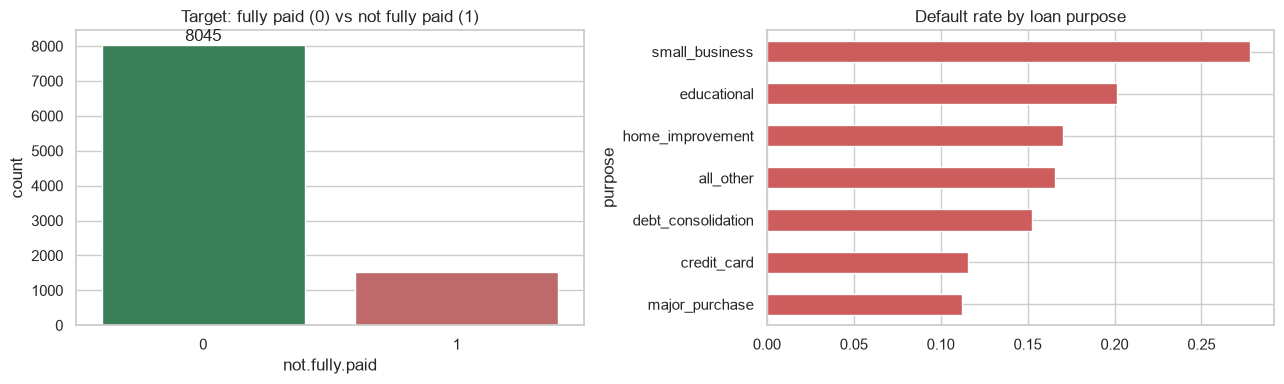

Default rate: 16.0%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = sns.countplot(x=df["not.fully.paid"], ax=axes[0], palette=["seagreen", "indianred"])
ax.bar_label(ax.containers[0]); ax.set_title("Target: fully paid (0) vs not fully paid (1)")
rate = df.groupby("purpose")["not.fully.paid"].mean().sort_values()
rate.plot.barh(ax=axes[1], color="indianred"); axes[1].set_title("Default rate by loan purpose")
plt.tight_layout(); plt.show()
print(f"Default rate: {df['not.fully.paid'].mean():.1%}")

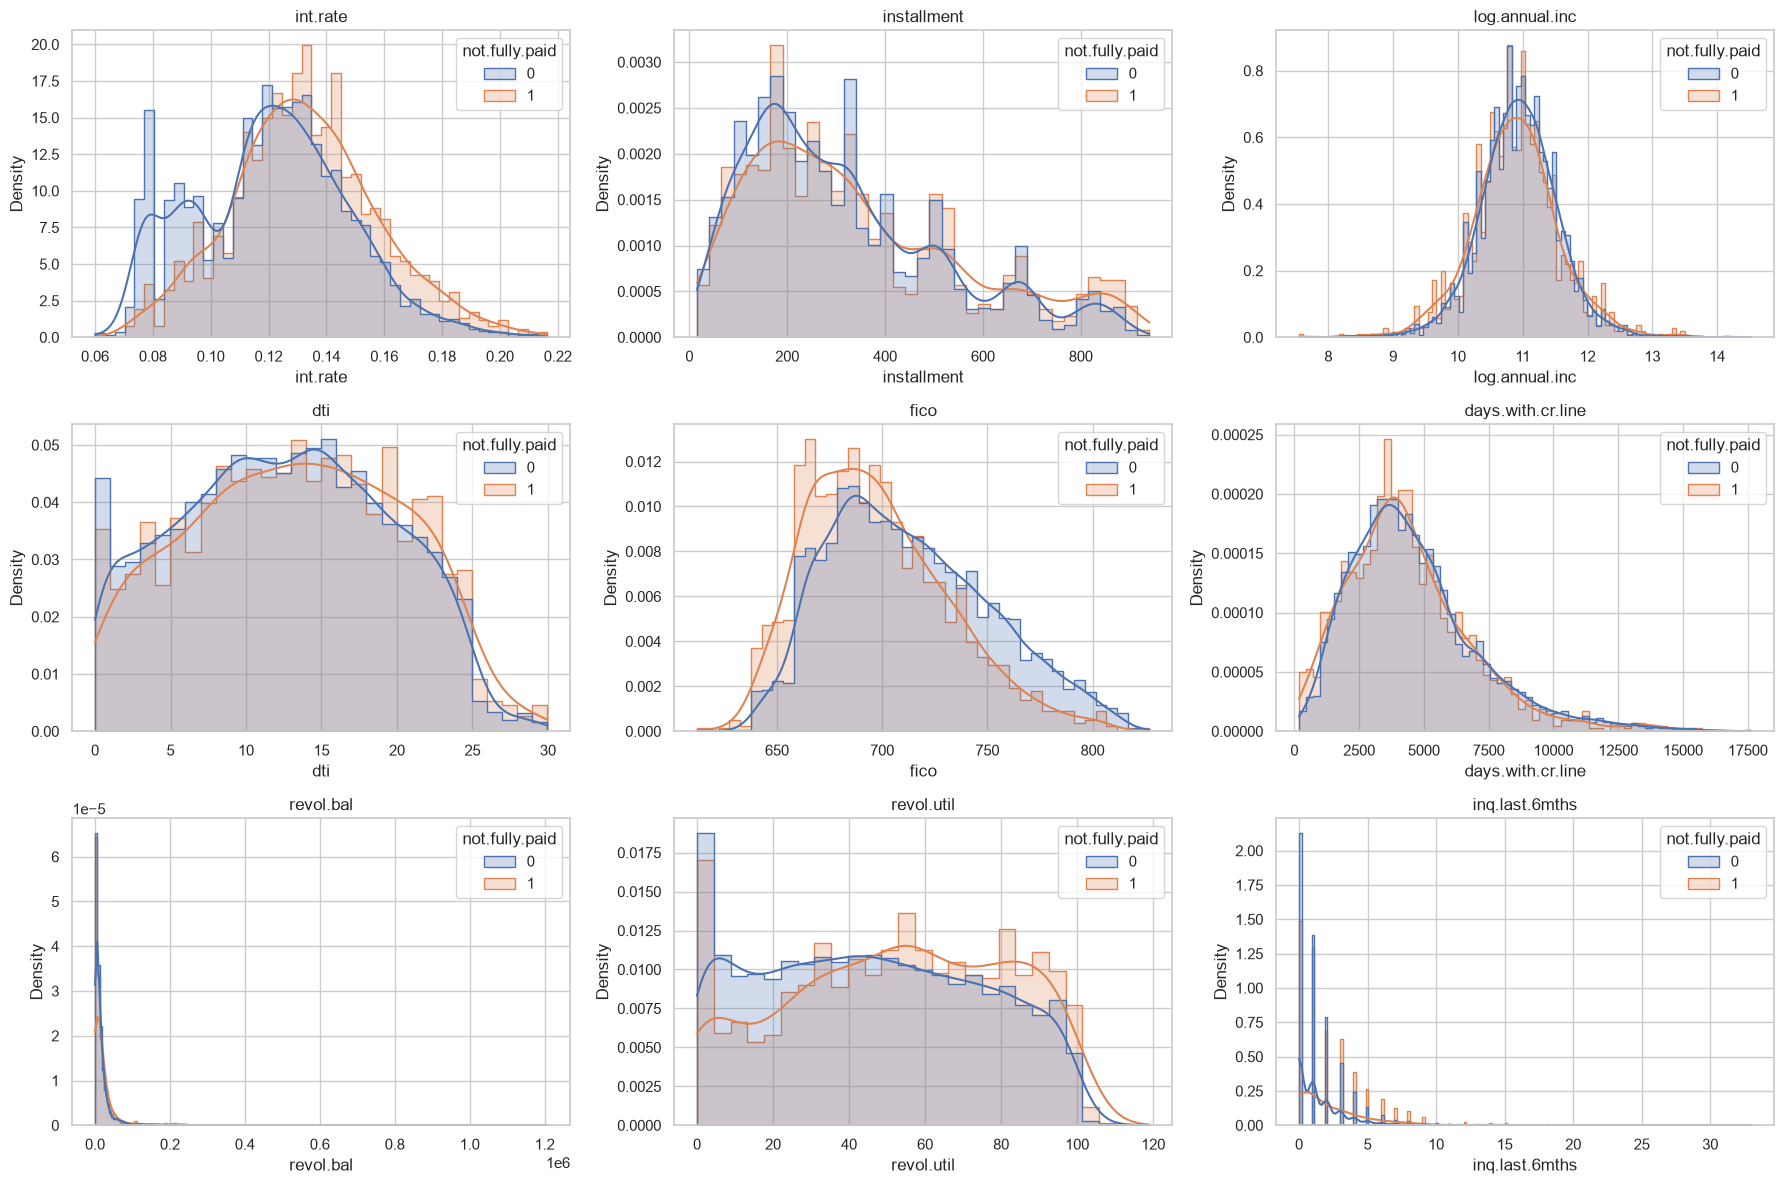

In [5]:
num_cols = ["int.rate", "installment", "log.annual.inc", "dti", "fico", "days.with.cr.line", "revol.bal", "revol.util", "inq.last.6mths"]
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=c, hue="not.fully.paid", kde=True, stat="density", common_norm=False, ax=ax, element="step")
    ax.set_title(c)
plt.tight_layout(); plt.show()

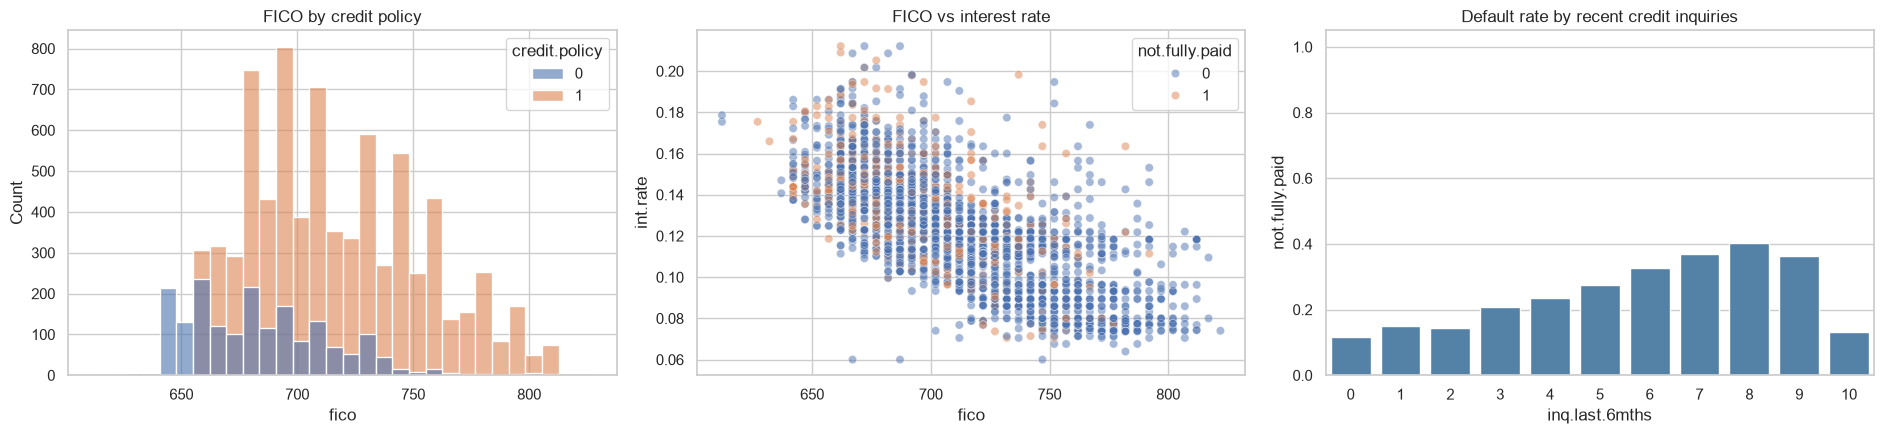

not.fully.paid,0,1
int.rate,0.121,0.132
installment,314.574,342.785
log.annual.inc,10.941,10.885
dti,12.494,13.196
fico,713.327,697.828
days.with.cr.line,4592.633,4393.541
revol.bal,16122.724,21066.294
revol.util,45.760,52.255
inq.last.6mths,1.434,2.331
credit.policy,0.832,0.661


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
sns.histplot(data=df, x="fico", hue="credit.policy", ax=axes[0], bins=30, alpha=0.6); axes[0].set_title("FICO by credit policy")
sns.scatterplot(data=df.sample(3000, random_state=SEED), x="fico", y="int.rate", hue="not.fully.paid", alpha=0.5, ax=axes[1]); axes[1].set_title("FICO vs interest rate")
sns.barplot(data=df, x="inq.last.6mths", y="not.fully.paid", errorbar=None, ax=axes[2], color="steelblue"); axes[2].set_title("Default rate by recent credit inquiries")
axes[2].set_xlim(-0.5, 10.5)
plt.tight_layout(); plt.show()
df.groupby("not.fully.paid")[num_cols + ["credit.policy", "delinq.2yrs", "pub.rec"]].mean().T.round(3)

**EDA insights**
* Borrowers who did **not** fully pay have **higher interest rates, lower FICO scores, more credit inquiries in the last 6 months** and
  are more often **outside the credit policy** (`credit.policy = 0`).
* **Small-business** loans have the highest default rate; **major purchases** and **credit cards** the lowest.
* Interest rate is set largely from FICO: the two are strongly negatively related.

## 3. Additional feature engineering — drop strongly correlated features

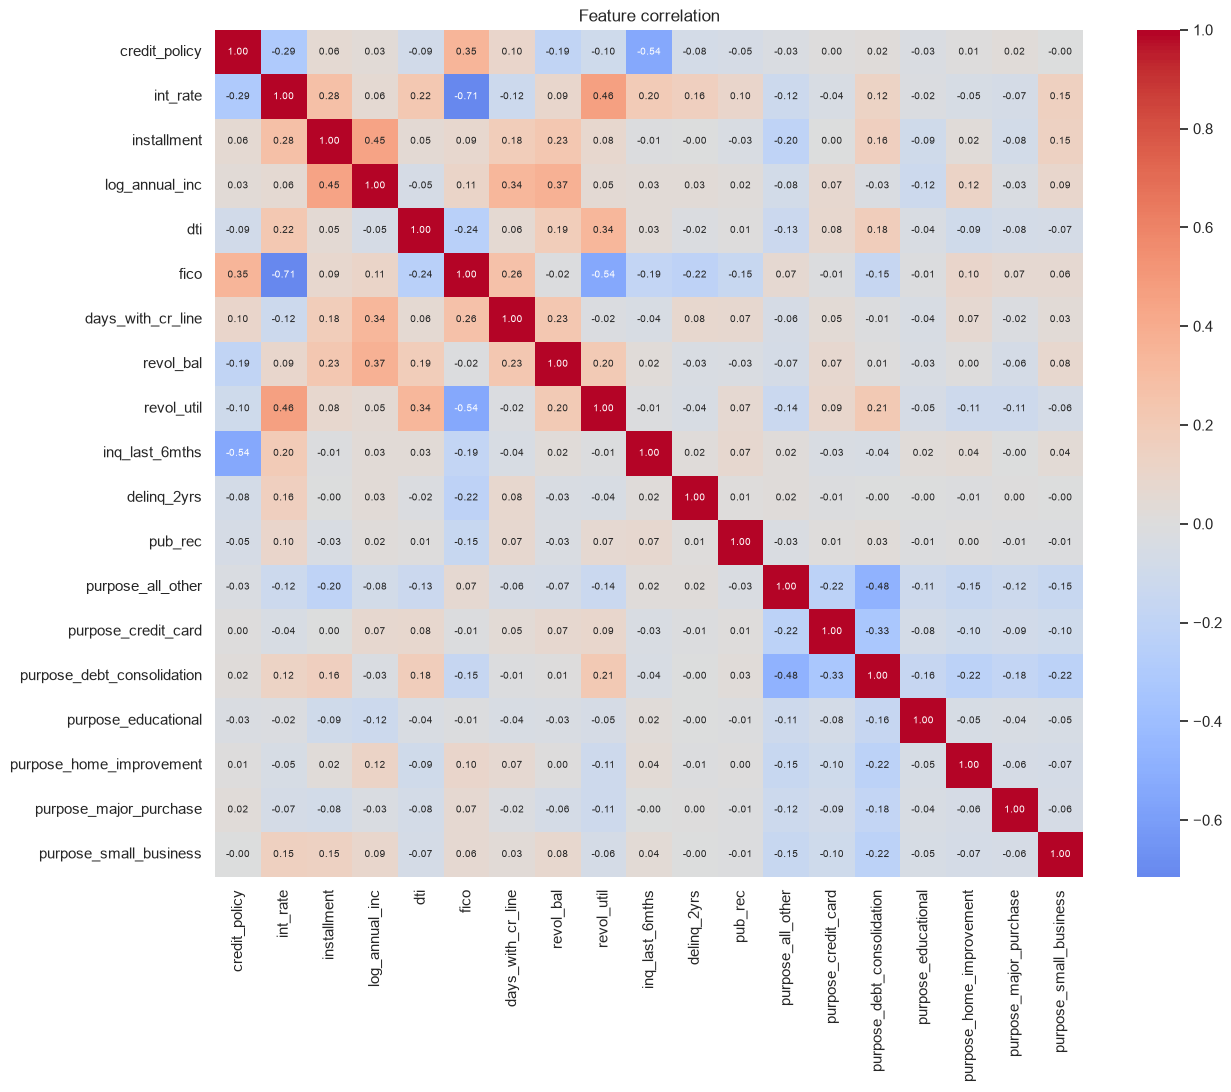

Strongly correlated pairs (|r| > 0.7):
 int_rate  fico    0.714821
dtype: float64


In [7]:
corr = df_enc.drop(columns=[target]).corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Feature correlation"); plt.show()

THRESH = 0.7
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().loc[lambda s: s > THRESH].sort_values(ascending=False)
print("Strongly correlated pairs (|r| > 0.7):\n", pairs)

`int.rate` and `fico` are strongly correlated (|r| ≈ 0.71). Interest rate is derived by LendingClub largely from FICO plus other risk factors,
so it carries redundant information. Of the pair we drop the one **less correlated with the target**.

In [8]:
target_corr = df_enc.corr()[target].abs()
to_drop = []
for (a, b), _ in pairs.items():
    drop = a if target_corr[a] < target_corr[b] else b
    if drop not in to_drop: to_drop.append(drop)
print("Correlation with target:\n", target_corr[[c for p in pairs.index for c in p]].round(3))
print("Dropping:", to_drop)
data = df_enc.drop(columns=to_drop)
X, y = data.drop(columns=[target]), data[target]
print("Final features:", X.shape[1])

Correlation with target:
 int_rate    0.16
fico        0.15
Name: not_fully_paid, dtype: float64
Dropping: ['fico']
Final features: 18


## 4. Modeling — Keras neural network
* Stratified **70 / 15 / 15** train / validation / test split, standardisation fitted on train only.
* Imbalance handled with **class weights** (keeps every real example; penalises missing a default more).
* Network: Dense(64) → Dropout → Dense(32) → Dropout → Dense(1, sigmoid), with early stopping on validation AUC.

In [9]:
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=SEED)
scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(a) for a in (X_train, X_val, X_test))
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print("Shapes:", X_train_s.shape, X_val_s.shape, X_test_s.shape, "| class weights:", {k: round(v, 3) for k, v in class_weight.items()})

Shapes: (6704, 18) (1437, 18) (1437, 18) | class weights: {0: np.float64(0.595), 1: np.float64(3.124)}


In [10]:
def build_model(n_features):
    model = keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(64, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
        keras.layers.BatchNormalization(),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(32, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="recall"),
                           keras.metrics.Precision(name="precision"), "accuracy"])
    return model

model = build_model(X_train_s.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,585 (14.00 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 128 (512.00 B)

Epochs trained: 53


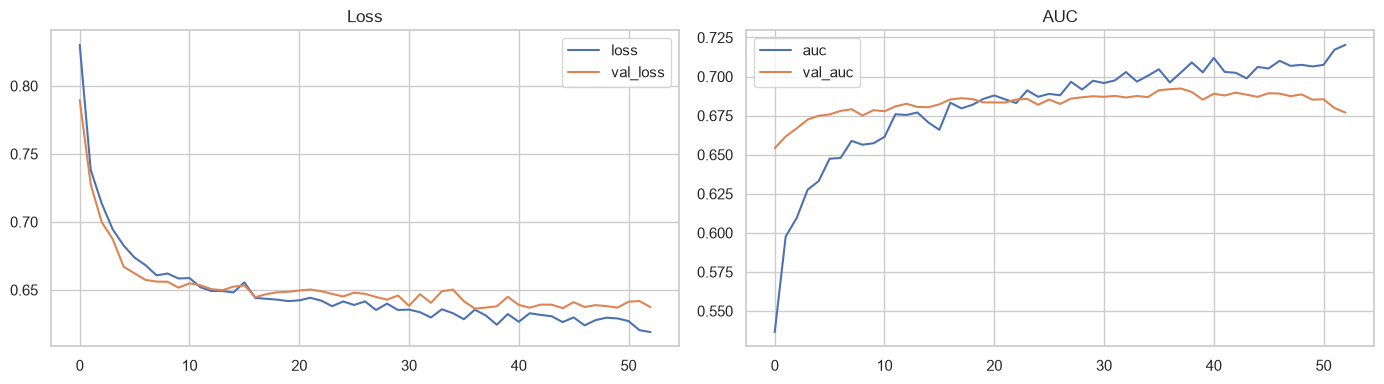

In [11]:
early = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=15, restore_best_weights=True)
history = model.fit(X_train_s, y_train, validation_data=(X_val_s, y_val), epochs=200, batch_size=128,
                    class_weight=class_weight, callbacks=[early], verbose=0)
print("Epochs trained:", len(history.history["loss"]))

hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hist[["loss", "val_loss"]].plot(ax=axes[0], title="Loss"); hist[["auc", "val_auc"]].plot(ax=axes[1], title="AUC")
plt.tight_layout(); plt.show()

### Evaluation on the held-out test set

Test ROC-AUC: 0.7030

                precision    recall  f1-score   support

    Fully paid      0.910     0.638     0.750      1207
Not fully paid      0.261     0.670     0.375       230

      accuracy                          0.643      1437
     macro avg      0.585     0.654     0.563      1437
  weighted avg      0.806     0.643     0.690      1437



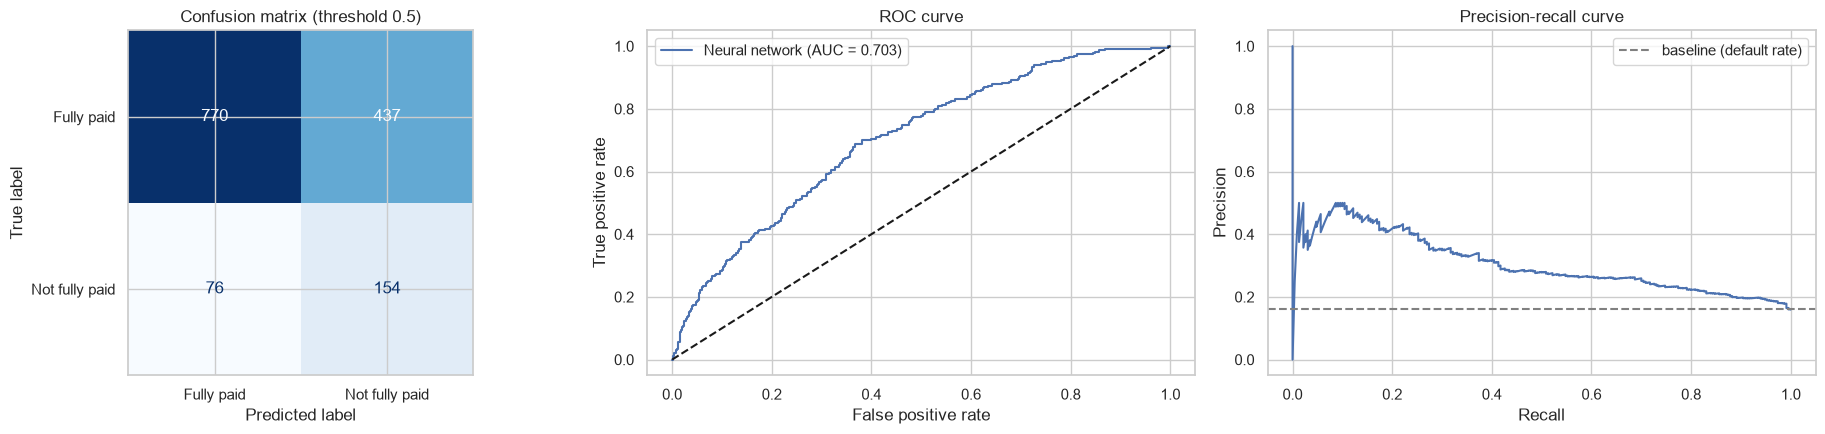

In [12]:
proba = model.predict(X_test_s, verbose=0).ravel()
pred = (proba >= 0.5).astype(int)
auc = roc_auc_score(y_test, proba)
print(f"Test ROC-AUC: {auc:.4f}\n")
print(classification_report(y_test, pred, target_names=["Fully paid", "Not fully paid"], digits=3))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Fully paid", "Not fully paid"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (threshold 0.5)")
fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, label=f"Neural network (AUC = {auc:.3f})"); axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC curve"); axes[1].legend()
prec, rec, thr = precision_recall_curve(y_test, proba)
axes[2].plot(rec, prec); axes[2].axhline(y_test.mean(), ls="--", color="grey", label="baseline (default rate)")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].set_title("Precision-recall curve"); axes[2].legend()
plt.tight_layout(); plt.show()

In [13]:
# Baseline comparison: logistic regression on the same features
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train_s, y_train)
print(f"Logistic regression baseline test AUC: {roc_auc_score(y_test, lr.predict_proba(X_test_s)[:, 1]):.4f}")
print(f"Neural network test AUC:              {auc:.4f}")

Logistic regression baseline test AUC: 0.6862
Neural network test AUC:              0.7030


## Conclusion
* `fico` was dropped because it is strongly correlated with `int.rate` (|r| ≈ 0.71) and `int.rate` carries more signal about default.
* The **neural network** (class weights + early stopping) reaches a test **ROC-AUC ≈ 0.70** and catches **≈ 67% of defaulted loans**
  (recall), at the cost of many false alarms (precision ≈ 0.26). It slightly outperforms a logistic-regression baseline (AUC ≈ 0.69).
  The modest AUC reflects the dataset: the available features only weakly separate good and bad loans.
* Key risk signals: **low FICO / high interest rate, many recent credit inquiries, not meeting credit policy, small-business purpose**.
* For a lender, recall on defaults matters more than precision (a missed default costs far more than a declined good loan); the decision
  threshold can be moved along the precision-recall curve to match the business's risk appetite.